# Classification classe comestible

Lien Kaggle: https://www.kaggle.com/competitions/playground-series-s4e8/data?select=test.csv <br>
Doc scikit: https://scikit-learn.org/stable/ <br>
Doc pandas: https://pandas.pydata.org/docs/

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer, KNNImputer

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder, FunctionTransformer

from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV

#distribution pour RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

#Score pour tester et la validation croisé
from sklearn.metrics import make_scorer, matthews_corrcoef

import time

#Experimental
from sklearn.experimental import enable_halving_search_cv  # noqa
from sklearn.model_selection import HalvingRandomSearchCV

# 1 CSV 

In [2]:
train=pd.read_csv('data_miss/train.csv', index_col='id')
test=pd.read_csv('data_miss/test.csv', index_col='id')

In [7]:
quanti=list(train.select_dtypes(include=["float64"]).columns)
quali=list(train.select_dtypes(include=["object"]).drop(columns="class").columns)
train_y=train["class"]
train_x=train.drop(columns="class")

# 2 Analyse des données

In [15]:
train.head()

,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
id,,,,,,,,,,,,,,,,,,,,,
0,e,8.80,f,s,u,f,a,c,w,4.51,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,p,4.51,x,h,o,f,a,c,n,4.79,...,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,e,6.94,f,s,b,f,x,c,w,6.85,...,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,e,3.88,f,y,g,f,s,NaN,g,4.16,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,e,5.85,x,l,w,f,d,NaN,w,3.37,...,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a


<Axes: xlabel='id', ylabel='class'>

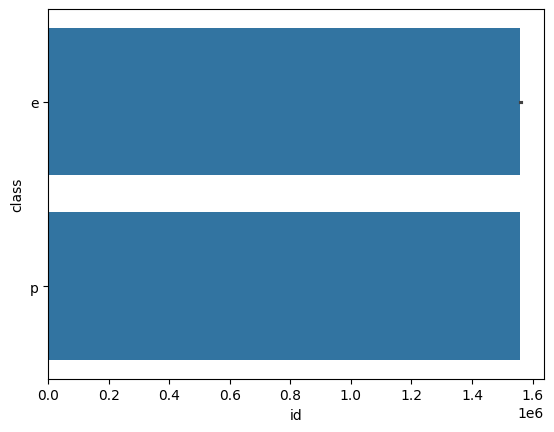

In [39]:
sns.barplot(train["class"])

Les classes cibles sont équilibrées

## 2.1 Types des données

In [14]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3116945 entries, 0 to 3116944
Data columns (total 21 columns):
 #   Column                Dtype  
---  ------                -----  
 0   class                 str    
 1   cap-diameter          float64
 2   cap-shape             str    
 3   cap-surface           str    
 4   cap-color             str    
 5   does-bruise-or-bleed  str    
 6   gill-attachment       str    
 7   gill-spacing          str    
 8   gill-color            str    
 9   stem-height           float64
 10  stem-width            float64
 11  stem-root             str    
 12  stem-surface          str    
 13  stem-color            str    
 14  veil-type             str    
 15  veil-color            str    
 16  has-ring              str    
 17  ring-type             str    
 18  spore-print-color     str    
 19  habitat               str    
 20  season                str    
dtypes: float64(3), str(18)
memory usage: 499.4 MB


Text(0.5, 1.0, 'Count Columns By Datatypes')

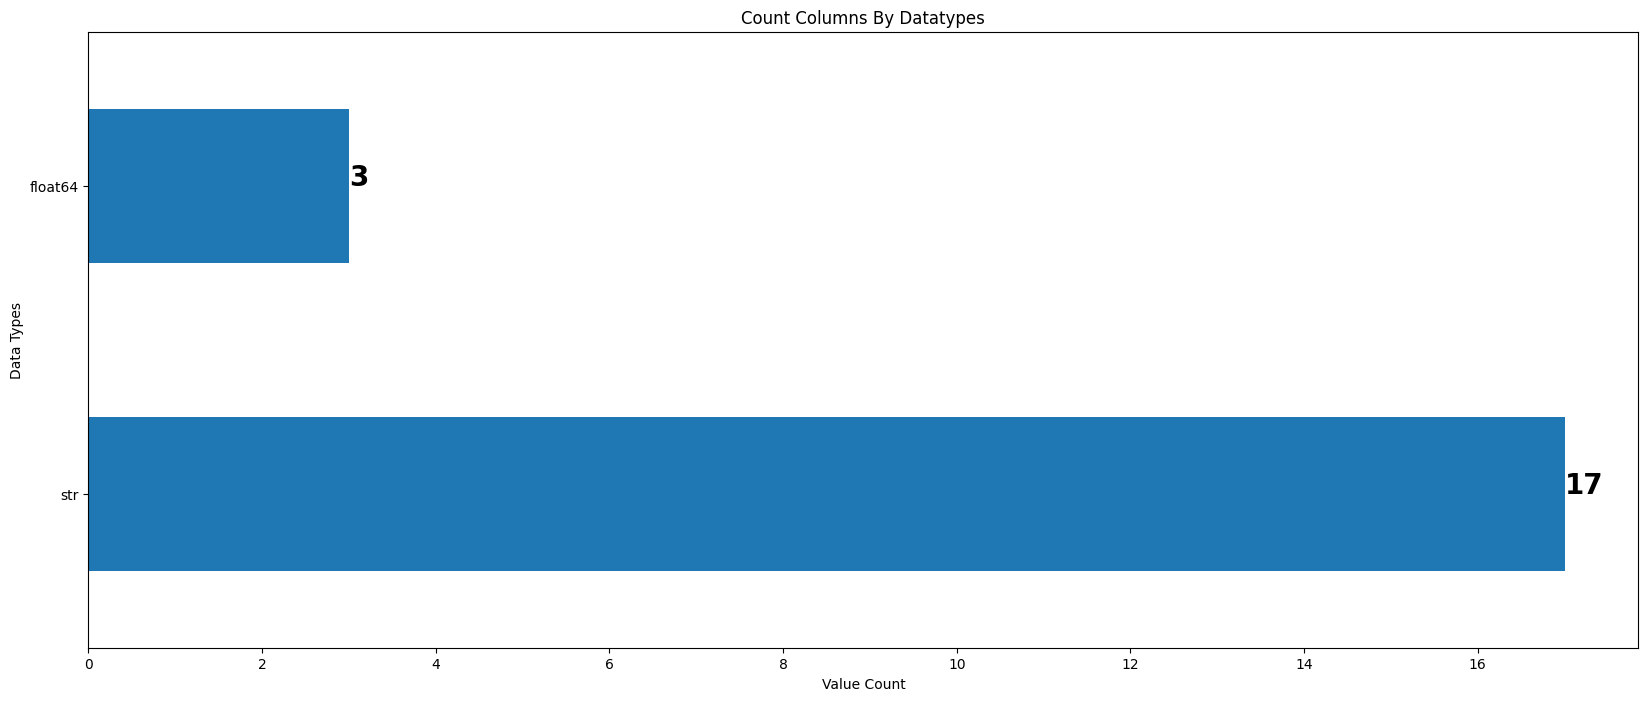

In [22]:
test.dtypes.value_counts().plot(kind="barh", figsize=(20,8))
for i, v in enumerate(test.dtypes.value_counts()):
    plt.text(v, i, str(v), fontweight='bold', fontsize = 20)
plt.xlabel("Value Count")
plt.ylabel("Data Types")
plt.title("Count Columns By Datatypes")

## 2.2 Données manquantes et dupliquées

In [27]:
#Pourcentage de données manquante
print("% Donnnée manquante qualitative dans train")
print(train[quali].isnull().sum()/train[quali].apply(len) *100)
print("% Donnnée manquante qualitative dans test")
print(test[quali].isnull().sum()/test[quali].apply(len) *100)

% Donnnée manquante qualitative dans train
cap-shape                0.001283
cap-surface             21.528227
cap-color                0.000385
does-bruise-or-bleed     0.000257
gill-attachment         16.809280
gill-spacing            40.373988
gill-color               0.001829
stem-root               88.452732
stem-surface            63.551362
stem-color               0.001219
veil-type               94.884350
veil-color              87.936970
has-ring                 0.000770
ring-type                4.134818
spore-print-color       91.425482
habitat                  0.001444
season                   0.000000
dtype: float64
% Donnnée manquante qualitative dans test
cap-shape                0.001492
cap-surface             21.506821
cap-color                0.000626
does-bruise-or-bleed     0.000481
gill-attachment         16.834796
gill-spacing            40.404694
gill-color               0.002358
stem-root               88.452543
stem-surface            63.595327
stem-color      

In [28]:
#Vérification données dupliquer
print(test.duplicated().sum())
print(train.duplicated().sum())
print("Pas de données dupliqués")

0
0
Pas de données dupliqués


## 2.3 Données numériques

In [16]:
train.describe()

,cap-diameter,stem-height,stem-width
count,3.116941e+06,3.116945e+06,3.116945e+06
mean,6.309848e+00,6.348333e+00,1.115379e+01
std,4.657931e+00,2.699755e+00,8.095477e+00
min,3.000000e-02,0.000000e+00,0.000000e+00
25%,3.320000e+00,4.670000e+00,4.970000e+00
50%,5.750000e+00,5.880000e+00,9.650000e+00
75%,8.240000e+00,7.410000e+00,1.563000e+01
max,8.067000e+01,8.872000e+01,1.029000e+02


In [13]:
df1=train[quanti].melt()
df2=train[quanti].melt()
df2["value"]=np.log1p(df2["value"])

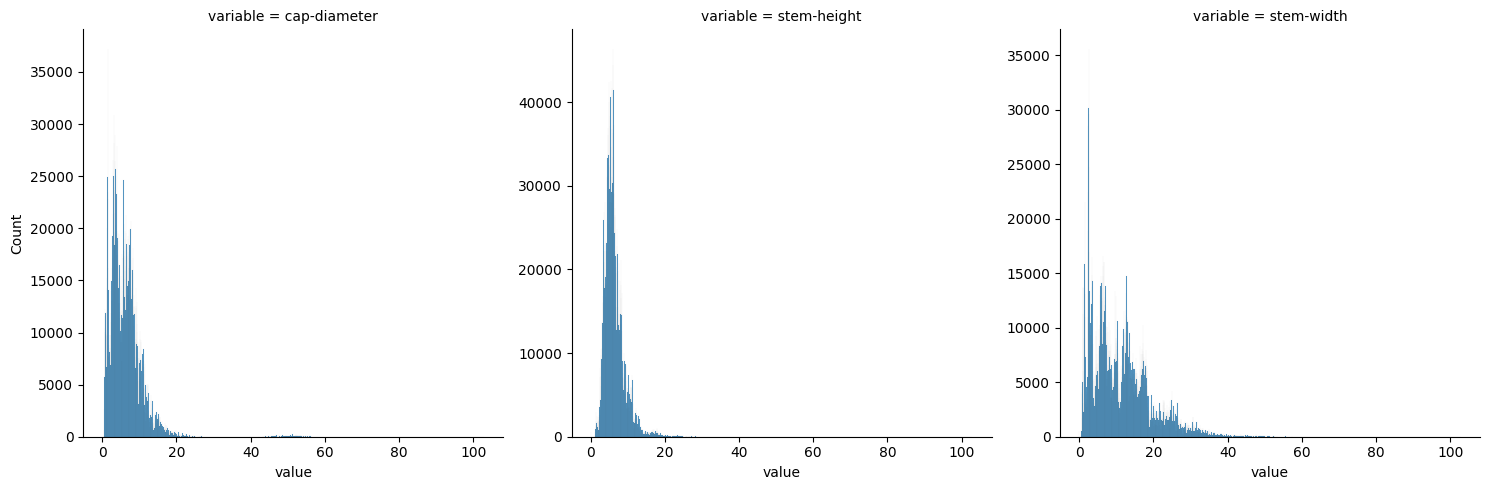

In [14]:
sns.displot(df1,x="value",col="variable",facet_kws={"sharex": False, "sharey": False})

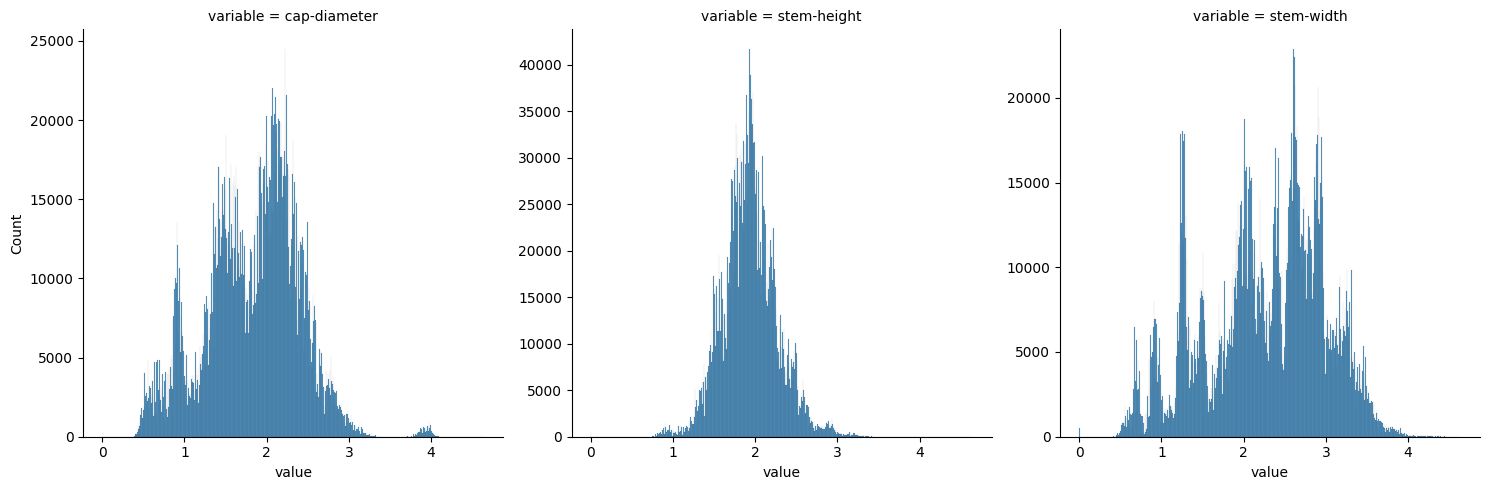

In [16]:
sns.displot(df2,x="value",col="variable",facet_kws={"sharex": False, "sharey": False})

Les colonnes numériques sont concentré à droite avec des valeurs extrêmes. Passer au Log donne une distribution quasi-normale, ça pourrait être plus intéressant sur les modèles qui LogisticRegression, (Linear)SVC et KNeighborsClassifier.

## 2.4 Données Quantitatives

In [32]:
#nombre de modalité qualitative
print(train[quali].nunique())

cap-shape               74
cap-surface             83
cap-color               78
does-bruise-or-bleed    26
gill-attachment         78
gill-spacing            48
gill-color              63
stem-root               38
stem-surface            60
stem-color              59
veil-type               22
veil-color              24
has-ring                23
ring-type               40
spore-print-color       32
habitat                 52
season                   4
dtype: int64


In [34]:
#On se donne un seuil de proportion en dessous duquel on regroupe les modalité dans la même catégorie "Rare".
#On regarde combien de à combien de modalité on tombe
seuil=0.01

dic={ c : { "Nbr de modalité": train[c].nunique(), "% Données manquantes": round(train[c].isnull().sum()/train[c].size *100,2), "Nbr modalité >= seuil": (train[c].value_counts(normalize=True)>= seuil).sum() , "% modalité >= seuil": round(train[c].value_counts(normalize=True).loc[lambda s: s >= 0.05].sum(),2) } for c in quali }
pd.DataFrame(dic)

,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
Nbr de modalité,74.0,83.00,78.00,26.0,78.00,48.00,63.00,38.00,60.00,59.00,22.00,24.00,23.0,40.00,32.00,52.0,4.00
% Données manquantes,0.0,21.53,0.00,0.0,16.81,40.37,0.00,88.45,63.55,0.00,94.88,87.94,0.0,4.13,91.43,0.0,0.00
Nbr modalité >= seuil,7.0,11.00,12.00,2.0,7.00,3.00,12.00,4.00,7.00,9.00,1.00,6.00,2.0,7.00,7.00,5.0,4.00
% modalité >= seuil,0.9,0.84,0.87,1.0,0.95,1.00,0.85,1.00,0.97,0.83,1.00,0.90,1.0,0.83,0.93,0.9,0.95


En regroupant les valeur rare en dessous de 1% de fréquence on perd au maximum 17% de l'information en réduisant énormément le nombre de modalité.  
On pourrait vérifier si les modalité rare apportent beaucoups d'informations c'est à dire si elle sont à majorité dans une classe de la cible qui est équilibré de base.

In [15]:
#On regarde aussi avec un seuil de 5%
seuil=0.05

dic2={ c : { "Nbr de modalité": train[c].nunique(), "% Données manquantes": round(train[c].isnull().sum()/train[c].size *100,2), "Nbr modalité >= seuil": (train[c].value_counts(normalize=True)>= seuil).sum() , "% modalité >= seuil": round(train[c].value_counts(normalize=True).loc[lambda s: s >= 0.05].sum(),2) } for c in quali }
pd.DataFrame(dic2)

,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
Nbr de modalité,74.0,83.00,78.00,26.0,78.00,48.00,63.00,38.00,60.00,59.00,22.00,24.00,23.0,40.00,32.00,52.0,4.00
% Données manquantes,0.0,21.53,0.00,0.0,16.81,40.37,0.00,88.45,63.55,0.00,94.88,87.94,0.0,4.13,91.43,0.0,0.00
Nbr modalité >= seuil,4.0,7.00,6.00,2.0,6.00,3.00,6.00,4.00,6.00,3.00,1.00,3.00,2.0,1.00,4.00,3.0,3.00
% modalité >= seuil,0.9,0.84,0.87,1.0,0.95,1.00,0.85,1.00,0.97,0.83,1.00,0.90,1.0,0.83,0.93,0.9,0.95


# 3 Traitement des données et Recherche de modèle 

In [8]:
#on fait des test sur un sous-ensemble du dataframe
df_train, _ = train_test_split(train,train_size=0.05,stratify=train["class"])
#on sépare la colonne cible
df_train_x=df_train.drop(columns="class")
df_train_y=df_train["class"]

Flow chart choix du modèle  
Lien: https://scikit-learn.org/stable/machine_learning_map.html  

On test sur les modèles suivants :  
1. Modèles simple de classifications
   1. LogisticRegression et LogisticRegressionCV
   2. DecisionTreeClassifier et RandomForestClassifier
2. En suivant la flow chart
   1. LinearSVC  
   2. KNeighborsClassifier
   3. GradientBoostingClassifier et HistGradientBoostingClassifier
   4. SVC

On utilise Matthews correlation coefficient pour choisir le meilleur modèle.  

## 3.1 Modèles de bases

### 3.1.1 Régression Logistique
On teste LogisticRegression et LogisticRegressionCV qui en plus de LogisticRegression teste plusieurs valeurs d'un paramètre du modèle pour choisir le meilleur.  

Pour ce modèle on va traité de la façon suivante : 
1. Colonnes numériques
   1. SimpleImputer("median")
   2. Passer au log
   3. StandardScaler()
2. Colonne catégorielles
   1. SimpleImputer("constant")
   2. OneHotEncoder(seuil pour une colonne infrequent)

In [9]:
CT_LR_quanti=make_pipeline(SimpleImputer(strategy="median"),FunctionTransformer(np.log1p),StandardScaler())
CT_LR_quali=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OneHotEncoder(min_frequency=0.01,handle_unknown="infrequent_if_exist"))

CT_LR=make_column_transformer([CT_LR_quali,quali],[CT_LR_quanti,quanti],verbose_feature_names_out=False)

Pipe_LR=make_pipeline(CT_LR,LogisticRegression(max_iter=1000))
Pipe_LRCV=make_pipeline(CT_LR,LogisticRegressionCV(max_iter=1000))

In [10]:
Pipe_LR

,steps,"[('columntransformer', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [11]:
Pipe_LRCV

,steps,"[('columntransformer', ...), ('logisticregressioncv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


### 3.1.2 Arbre de décision et Forêts aléatoires
Lien sur les arbres : https://scikit-learn.org/stable/modules/tree.html#tree  
Lien sur les ensembles : https://scikit-learn.org/stable/modules/ensemble.html#ensemble

On va traité les données différemment pour les arbres et les forêts :
1. Colonnes numériques
   1. SimpleImputer("median")
2. Colonnes catégorielles
   1. SimpleImputer("constant")
   2. OrdinalEncoder(sans seuil)

In [12]:
CT_tree_quali=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1))

CT_tree=make_column_transformer([CT_tree_quali,quali],[SimpleImputer(strategy="median"),quanti],verbose_feature_names_out=False)

Pipe_tree=make_pipeline(CT_tree,DecisionTreeClassifier())
Pipe_forest=make_pipeline(CT_tree,RandomForestClassifier())

In [13]:
Pipe_tree

,steps,"[('columntransformer', ...), ('decisiontreeclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('simpleimputer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [14]:
Pipe_forest

,steps,"[('columntransformer', ...), ('randomforestclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('simpleimputer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


### 3.1.3 Comparaison des modèles

In [11]:
model_classique={"Régression Logistique":Pipe_LR,"Régression Logistique CV":Pipe_LRCV,"Arbre de décision":Pipe_tree,"Forêt aléatoire":Pipe_forest}

for i in model_classique:
    model_classique[i].fit(df_train_x,df_train_y)

tab_score_classique=pd.DataFrame({
   i : {
        "Score" : matthews_corrcoef(model_classique[i].predict(df_train_x),df_train_y)
    }
    for i in model_classique
})
tab_score_classique

C:\Users\mathe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\mathe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
C:\Users\mathe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be 

,Régression Logistique,Régression Logistique CV,Arbre de décision,Forêt aléatoire
Score,0.708369,0.70887,1.0,0.999961


## 3.2 Modèles Flowchart

Pour LinearSVC et SVC on utilise le même prétraitement que LogisticRegression.  
Pour KNeighborsClassifier on utilise aussi le même prétraitement que LogisticRegression mais avec un palier à 5% pour les variables rares.  
Pour GradientBoostingClassifier on utilise celui des arbres.  
Pour HistGradientBoostingClassifier on ne traite pas les données numériques et pour les qualitatives on fait un ordinal encoder 

### 3.2.1 Définition des modèles

In [15]:
CT_KN_quali=CT_LR_quali=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OneHotEncoder(min_frequency=0.05,handle_unknown="infrequent_if_exist"))
 
CT_hist=make_column_transformer([OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1),quali],remainder="passthrough",verbose_feature_names_out=False)
CT_KN=make_column_transformer([CT_KN_quali,quali],[SimpleImputer(strategy="median"),quanti],verbose_feature_names_out=False)

Pipe_LSVC=make_pipeline(CT_LR,LinearSVC())
Pipe_SVC=make_pipeline(CT_LR,SVC())
Pipe_GB=make_pipeline(CT_tree,GradientBoostingClassifier())
Pipe_HGB=make_pipeline(CT_hist,HistGradientBoostingClassifier())
Pipe_KN=make_pipeline(CT_KN,KNeighborsClassifier())


In [16]:
Pipe_LSVC

,steps,"[('columntransformer', ...), ('linearsvc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [17]:
Pipe_KN

,steps,"[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('simpleimputer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [18]:
Pipe_GB

,steps,"[('columntransformer', ...), ('gradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('simpleimputer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [19]:
Pipe_SVC

,steps,"[('columntransformer', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [20]:
Pipe_HGB

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinalencoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


### 3.2.2 Comparaison des modèles

In [18]:
model_flow={ "Linear SVC":Pipe_LSVC, "K Neighbors":Pipe_KN, "Gradient Boosting":Pipe_GB, "SVC":Pipe_SVC, "Hist Gradient Boosting":Pipe_HGB }

for i in model_flow:
    model_flow[i].fit(df_train_x,df_train_y)

tab_score_flow=pd.DataFrame({
   i : {
        "Score" : matthews_corrcoef(model_flow[i].predict(df_train_x),df_train_y)
    }
    for i in model_flow
})
tab_score_flow

,Linear SVC,K Neighbors,Gradient Boosting,SVC,Hist Gradient Boosting
Score,0.706813,0.981067,0.873884,0.983289,0.978822


## 3.3 Résultats

In [20]:
tab_score_classique.join(tab_score_flow).T

,Score
Régression Logistique,0.708369
Régression Logistique CV,0.708870
Arbre de décision,1.000000
Forêt aléatoire,0.999961
Linear SVC,0.706813
K Neighbors,0.981067
Gradient Boosting,0.873884
SVC,0.983289
Hist Gradient Boosting,0.978822


## 3.4 Affinage Choix de modèle
Avec les scores obtenus on va se concentrer sur les modèles suivants :
1. Forêts aléatoire
2. K Neighbors
3. SVC
4. Hist Grad Boosting

In [27]:
model_choisi={"Forêt aléatoire":Pipe_forest,"K Neighbors":Pipe_KN,"SVC":Pipe_SVC, "Hist Gradient Boosting":Pipe_HGB}

t_fit=[]
for i in model_choisi :
    t_d=time.perf_counter()
    model_choisi[i].fit(df_train_x,df_train_y)
    t_f=time.perf_counter()
    t_fit.append(t_f-t_d)
t_fit

[38.156868499994744, 6.604295999975875, 511.1552915999782, 7.056105900002876]

SVC est trop long avec seulemenent 10 % des données donc on le retire

In [28]:
t_fit=[]
for i in model_choisi :
    t_d=time.perf_counter()
    model_choisi[i].predict(df_train_x)
    t_f=time.perf_counter()
    t_fit.append(t_f-t_d)
t_fit

[15.639381599990884, 2296.559752899979, 251.6475070999877, 1.7686720000056084]

Le K Neighbors est beaucoup trop long on va se concentré sur Forêt aléatoire est Hist Gradient Boosting

In [32]:
model_final={"Forêt aléatoire":Pipe_forest,"Hist Gradient Boosting":Pipe_HGB}

t_fit=[]
for i in model_final :
    t_d=time.perf_counter()
    model_final[i].fit(df_train_x,df_train_y)
    t_f=time.perf_counter()
    t_fit.append(t_f-t_d)
t_fit

[20.670343700010562, 2.929703400004655]

In [42]:
t_fit=[]
for i in model_final :
    t_d=time.perf_counter()
    model_final[i].predict(train_x)
    t_f=time.perf_counter()
    t_fit.append(t_f-t_d)
t_fit


KeyboardInterrupt



KeyboardInterrupt: 

# 4 Tuning des paramètres et validation croisé
On veut optimiser les paramètres des modèles pour améliorer le score.  
Parameter Tuning: https://scikit-learn.org/stable/modules/grid_search.html   
HistGradBoosting: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html#sklearn.ensemble.HistGradientBoostingClassifier   
RandomForest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier  


In [36]:
HistGradientBoostingClassifier().get_params()

{'categorical_features': 'from_dtype',
 'class_weight': None,
 'early_stopping': 'auto',
 'interaction_cst': None,
 'l2_regularization': 0.0,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_bins': 255,
 'max_depth': None,
 'max_features': 1.0,
 'max_iter': 100,
 'max_leaf_nodes': 31,
 'min_samples_leaf': 20,
 'monotonic_cst': None,
 'n_iter_no_change': 10,
 'random_state': None,
 'scoring': 'loss',
 'tol': 1e-07,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [37]:
RandomForestClassifier().get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Le paramètre n_jobs=-1 permet d'utiliser tous le processeur pour paralléliser la tâche et la rendre plus rapide.   
HistGradBoosting le fait déjà automatiquement.

On va réécrir les pipelines

## 4.1 Pipeline

In [21]:
#on fait des test sur un sous-ensemble du dataframe
df_train, _ = train_test_split(train,train_size=0.05,stratify=train["class"])
#on sépare la colonne cible
df_train_x=df_train.drop(columns="class")
df_train_y=df_train["class"]

In [22]:
CT_HGB=make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan),quali),remainder="passthrough",verbose_feature_names_out=False)
CT_quali_RF=make_pipeline(SimpleImputer(strategy="constant", fill_value="Manquant"),OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
CT_RF=make_column_transformer((CT_quali_RF, quali),(SimpleImputer(strategy="median", add_indicator=True), quanti),verbose_feature_names_out=False)

HGB=HistGradientBoostingClassifier(categorical_features=list(range(len(quali))))
RF=RandomForestClassifier(n_jobs=-1)

PHGB=make_pipeline(CT_HGB,HGB)
PRF=make_pipeline(CT_RF,RF)

modèles={"HGB":PHGB,"RF":PRF}

In [23]:
PHGB

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinalencoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [ ]:
PRF

In [ ]:
t_fit=[]
for i in modèles :
    t_d=time.perf_counter()
    modèles[i].fit(df_train_x,df_train_y)
    t_f=time.perf_counter()
    t_fit.append(t_f-t_d)
t_fit

In [24]:
t_pred=[]
for i in modèles :
    t_d=time.perf_counter()
    modèles[i].predict(df_train_x)
    t_f=time.perf_counter()
    t_pred.append(t_f-t_d)
t_pred

[1.0812799000004816, 1.07508450000023]

In [61]:
t_score=[]
for i in modèles :
    t_d=time.perf_counter()
    print(matthews_corrcoef(modèles[i].predict(train_x),train_y))
    t_f=time.perf_counter()
    t_score.append(t_f-t_d)
t_score

0.9802365881273206
0.9832132580665983


[58.471514400007436, 34.61980909999693]

## 4.2 Score et validation croisée

In [17]:
MCC=make_scorer(matthews_corrcoef)
CrossVal=StratifiedKFold(n_splits=3)

Pour utiliser randomized search on va donner a chaque paramètre auxquel on s'interessent une distribution ou un ensemble.  
A chaque cycle de la recherche chaque paramètre sera tiré aléatoirement selon la distribution ou aléatoirement dans l'ensemble.

Tuning HGB: https://sklearngeneticopt.rodrigo-arenas.com/versions/0.13/tutorials/tune-gradient-boosting  
Tuning RF : https://sklearngeneticopt.rodrigo-arenas.com/versions/0.13/tutorials/tune-random-forest#which-hyperparameters-actually-matter  

Le lien parle d'une méthode utilisant le package sklearn_genetic mais on va rester sur les outils du package de base en traduisant les Range de la façon suivante:  
1. Continuous(distribution="log-uniform") -> loguniform()
2. Integer() -> randint()
3. Continuous() -> uniform()

In [18]:
HGB_search={
    "histgradientboostingclassifier__learning_rate":loguniform(0.01,0.3),  #loguniform (0.01,0.3)
    "histgradientboostingclassifier__max_iter":randint(100,501), #Integer(100,500)
    "histgradientboostingclassifier__max_leaf_nodes":randint(15,128), #Integer(15,127)
    "histgradientboostingclassifier__min_samples_leaf":randint(10,101), #Integer(10,100)
    "histgradientboostingclassifier__l2_regularization":uniform(0.0,1.0), #Continuous(0.0,1.0)
    "histgradientboostingclassifier__max_features":uniform(0.3,0.7) #continuous(0.3,1.0)
}


RF_search={
    "randomforestclassifier__n_estimators": randint(50,501), #Integer(50, 500)
    "randomforestclassifier__max_depth": randint(3,26), #Integer(3, 25)
    "randomforestclassifier__min_samples_split": randint(2,21), #Integer(2, 20)
    "randomforestclassifier__min_samples_leaf": randint(1,11), #Integer(1, 10)
    "randomforestclassifier__max_features": ["sqrt","log2",None], #Categorical(["sqrt", "log2", None])
    "randomforestclassifier__max_samples": uniform(0.5,0.5), #Continuous(0.5, 1.0)
    "randomforestclassifier__min_impurity_decrease": uniform(0.0,0.01), #Continuous(0.0, 0.01)
}

In [139]:
HGB_RSCV=RandomizedSearchCV(PHGB, HGB_search, n_iter=40, scoring=MCC, cv=CrossVal, n_jobs=1, verbose=2)

HGB_RSCV.fit(df_train_x,df_train_y)

print(HGB_RSCV)
print(HGB_RSCV.best_params_)
print(HGB_RSCV.best_score_)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END histgradientboostingclassifier__l2_regularization=0.39884986460072225, histgradientboostingclassifier__learning_rate=0.0188949896991407, histgradientboostingclassifier__max_features=0.9391403842152952, histgradientboostingclassifier__max_iter=335, histgradientboostingclassifier__max_leaf_nodes=26, histgradientboostingclassifier__min_samples_leaf=24; total time=   7.2s
[CV] END histgradientboostingclassifier__l2_regularization=0.39884986460072225, histgradientboostingclassifier__learning_rate=0.0188949896991407, histgradientboostingclassifier__max_features=0.9391403842152952, histgradientboostingclassifier__max_iter=335, histgradientboostingclassifier__max_leaf_nodes=26, histgradientboostingclassifier__min_samples_leaf=24; total time=   7.1s
[CV] END histgradientboostingclassifier__l2_regularization=0.39884986460072225, histgradientboostingclassifier__learning_rate=0.0188949896991407, histgradientboostingclassifier__

In [140]:
RF_RSCV=RandomizedSearchCV(PRF, RF_search, n_iter=40, scoring=MCC, cv=CrossVal, n_jobs=1, verbose=2)

RF_RSCV.fit(df_train_x,df_train_y)

print(RF_RSCV)
print(RF_RSCV.best_params_)
print(RF_RSCV.best_score_)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END randomforestclassifier__max_depth=3, randomforestclassifier__max_features=None, randomforestclassifier__max_samples=0.8294798352089778, randomforestclassifier__min_impurity_decrease=0.009199765526014406, randomforestclassifier__min_samples_leaf=5, randomforestclassifier__min_samples_split=19, randomforestclassifier__n_estimators=87; total time=   3.5s
[CV] END randomforestclassifier__max_depth=3, randomforestclassifier__max_features=None, randomforestclassifier__max_samples=0.8294798352089778, randomforestclassifier__min_impurity_decrease=0.009199765526014406, randomforestclassifier__min_samples_leaf=5, randomforestclassifier__min_samples_split=19, randomforestclassifier__n_estimators=87; total time=   3.3s
[CV] END randomforestclassifier__max_depth=3, randomforestclassifier__max_features=None, randomforestclassifier__max_samples=0.8294798352089778, randomforestclassifier__min_impurity_decrease=0.009199765526014406,

In [141]:
HGB_HRSCV=HalvingRandomSearchCV(PHGB, HGB_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)

HGB_HRSCV.fit(train_x,train_y)

print(HGB_HRSCV)
print(HGB_HRSCV.best_params_)
print(HGB_HRSCV.best_score_)

n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 100000
max_resources_: 1800000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 18
n_resources: 100000
Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END histgradientboostingclassifier__l2_regularization=0.3848741498775309, histgradientboostingclassifier__learning_rate=0.029214958831473292, histgradientboostingclassifier__max_features=0.7495827031637223, histgradientboostingclassifier__max_iter=256, histgradientboostingclassifier__max_leaf_nodes=40, histgradientboostingclassifier__min_samples_leaf=85; total time=   4.8s
[CV] END histgradientboostingclassifier__l2_regularization=0.3848741498775309, histgradientboostingclassifier__learning_rate=0.029214958831473292, histgradientboostingclassifier__max_features=0.7495827031637223, histgradientboostingclassifier__max_iter=256, histgradientboostingclassifier__max_leaf_nodes=40, histgradientboostingclassifier__min_samp

In [34]:
RF_HRSCV=HalvingRandomSearchCV(PRF, RF_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)

RF_HRSCV.fit(train_x,train_y)

print(RF_HRSCV)
print(RF_HRSCV.best_params_)
print(RF_HRSCV.best_score_)

n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 100000
max_resources_: 1800000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 18
n_resources: 100000
Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END randomforestclassifier__max_depth=7, randomforestclassifier__max_features=log2, randomforestclassifier__max_samples=0.9275642852425807, randomforestclassifier__min_impurity_decrease=0.005088849674497547, randomforestclassifier__min_samples_leaf=1, randomforestclassifier__min_samples_split=5, randomforestclassifier__n_estimators=107; total time=   1.2s
[CV] END randomforestclassifier__max_depth=7, randomforestclassifier__max_features=log2, randomforestclassifier__max_samples=0.9275642852425807, randomforestclassifier__min_impurity_decrease=0.005088849674497547, randomforestclassifier__min_samples_leaf=1, randomforestclassifier__min_samples_split=5, randomforestclassifier__n_estimators=107; total time=   1.6s
[CV]

In [144]:
#pd.DataFrame(HGB_HRSCV.predict(test),index=test.index,columns=['class']).to_csv('result_HGB_HRSCV.csv')

In [145]:
#pd.DataFrame(RF_HRSCV.predict(test),index=test.index,columns=['class']).to_csv('result_RF_HRSCV.csv')

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinalencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.

In [15]:
from sklearn import set_config

temp={ "Linear SVC":Pipe_LSVC, "K Neighbors":Pipe_KN, "Gradient Boosting":Pipe_GB, "SVC":Pipe_SVC, "Hist Gradient Boosting":Pipe_HGB,
"Forêt aléatoire":Pipe_forest,"K Neighbors":Pipe_KN,"SVC":Pipe_SVC, "Hist Gradient Boosting":Pipe_HGB}

for i in temp :
    print(temp[i])

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(fill_value='Manquant',
                                                                                 strategy='constant')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.01))]),
                                                  ['cap-shape', 'cap-surface',
                                                   'cap-color',
                                                   'does-bruise-or-bleed',
                                                   'gill-attachment',
          

In [28]:
HGB_RSCV=RandomizedSearchCV(PHGB, HGB_search, n_iter=40, scoring=MCC, cv=CrossVal, n_jobs=1, verbose=2)
HGB_RSCV

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... 16]))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'histgradientboostingcl...fier__l2_regularization': <scipy.stats....0024F7C21FBD0>, 'histgradientboostingclassifier__learning_rate': <scipy.stats....0024F7D74C3B0>, 'histgradientboostingclassifier__max_features': <scipy.stats....0024F7D5EDBF0>, 'histgradientboostingclassifier__max_iter': <scipy.stats....0024F7C21D150>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``b

In [29]:
RF_RSCV=RandomizedSearchCV(PRF, RF_search, n_iter=40, scoring=MCC, cv=CrossVal, n_jobs=1, verbose=2)
RF_RSCV

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'randomforestclassifier__max_depth': <scipy.stats....0024F7DC7BF20>, 'randomforestclassifier__max_features': ['sqrt', 'log2', ...], 'randomforestclassifier__max_samples': <scipy.stats....0024F7DD3CE50>, 'randomforestclassifier__min_impurity_decrease': <scipy.stats....0024F7DD3D050>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_par

In [31]:
HGB_HRSCV=HalvingRandomSearchCV(PHGB, HGB_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)
HGB_HRSCV

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... 16]))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'histgradientboostingcl...fier__l2_regularization': <scipy.stats....0024F7C21FBD0>, 'histgradientboostingclassifier__learning_rate': <scipy.stats....0024F7D74C3B0>, 'histgradientboostingclassifier__max_features': <scipy.stats....0024F7D5EDBF0>, 'histgradientboostingclassifier__max_iter': <scipy.stats....0024F7C21D150>, ...}"
,"max_resources max_resources: int, default='auto'The maximum number of resources that any candidate is allowed to usefor a given iteration. By default, this is set ``n_samples`` when``resource='n_samples'`` (default), else an error is raised.",1800000
,"min_resources min_resources: {'exhaust', 'smallest'} or int, default='smallest'The minimum amount of resource that any candidate is allowed to usefor a given iteration. Equivalently, this defines the amount ofresources `r0` that are allocated for each candidate at the firstiteration.- 'smallest' is a heuristic that sets `r0` to a small value: - ``n_splits * 2`` when ``resource='n_samples'`` for a regression problem - ``n_classes * n_splits * 2`` when ``resource='n_samples'`` for a classification problem - ``1`` when ``resource != 'n_samples'``- 'exhaust' will set `r0` such that the **last** iteration uses as much resources as possible. Namely, the last iteration will use the highest value smaller than ``max_resources`` that is a multiple of both ``min_resources`` and ``factor``. In general, using 'exhaust' leads to a more accurate estimator, but is slightly more time consuming. 'exhaust' isn't available when `n_candidates='exhaust'`.Note that the amount of resources used at each iteration is always amultiple of ``min_resources``.",100000
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... note:: Due to implementation details, the folds produced by `cv` must be the same across multiple calls to `cv.split()`. For built-in `scikit-learn` iterators, this can be achieved by deactivating shuffling (`shuffle=False`), or by setting the `cv`'s `random_state` parameter to an integer.",StratifiedKFo...shuffle=False)
,"scoring scoring: str or callable, default=NoneScoring method to use to evaluate the predictions on the test set.- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",make_scorer(m...hod='predict')
,"verbose verbose: intControls the verbosity: the higher, the more messages.",2
,"n_candidates n_candidates: ""exhaust"" or int, default=""exhaust""The number of candidate parameters to sample, at the firstiteration. Using 'exhaust' will sample enough candidates so that thelast 

In [33]:
RF_HRSCV=HalvingRandomSearchCV(PHGB, HGB_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)
RF_HRSCV

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... 16]))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'histgradientboostingcl...fier__l2_regularization': <scipy.stats....0024F7C21FBD0>, 'histgradientboostingclassifier__learning_rate': <scipy.stats....0024F7D74C3B0>, 'histgradientboostingclassifier__max_features': <scipy.stats....0024F7D5EDBF0>, 'histgradientboostingclassifier__max_iter': <scipy.stats....0024F7C21D150>, ...}"
,"max_resources max_resources: int, default='auto'The maximum number of resources that any candidate is allowed to usefor a given iteration. By default, this is set ``n_samples`` when``resource='n_samples'`` (default), else an error is raised.",1800000
,"min_resources min_resources: {'exhaust', 'smallest'} or int, default='smallest'The minimum amount of resource that any candidate is allowed to usefor a given iteration. Equivalently, this defines the amount ofresources `r0` that are allocated for each candidate at the firstiteration.- 'smallest' is a heuristic that sets `r0` to a small value: - ``n_splits * 2`` when ``resource='n_samples'`` for a regression problem - ``n_classes * n_splits * 2`` when ``resource='n_samples'`` for a classification problem - ``1`` when ``resource != 'n_samples'``- 'exhaust' will set `r0` such that the **last** iteration uses as much resources as possible. Namely, the last iteration will use the highest value smaller than ``max_resources`` that is a multiple of both ``min_resources`` and ``factor``. In general, using 'exhaust' leads to a more accurate estimator, but is slightly more time consuming. 'exhaust' isn't available when `n_candidates='exhaust'`.Note that the amount of resources used at each iteration is always amultiple of ``min_resources``.",100000
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... note:: Due to implementation details, the folds produced by `cv` must be the same across multiple calls to `cv.split()`. For built-in `scikit-learn` iterators, this can be achieved by deactivating shuffling (`shuffle=False`), or by setting the `cv`'s `random_state` parameter to an integer.",StratifiedKFo...shuffle=False)
,"scoring scoring: str or callable, default=NoneScoring method to use to evaluate the predictions on the test set.- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",make_scorer(m...hod='predict')
,"verbose verbose: intControls the verbosity: the higher, the more messages.",2
,"n_candidates n_candidates: ""exhaust"" or int, default=""exhaust""The number of candidate parameters to sample, at the firstiteration. Using 'exhaust' will sample enough candidates so that thelast 